# Euro Trading Volume Regression Analysis with Multicollinearity check

This Python script performs data processing and regression analysis on Euro trading volume data. The process includes merging datasets, handling missing values, and applying feature engineering techniques such as trading time, weekday effects, trade direction, and instrument type. The script then runs an OLS regression model with all variables included, demonstrating how each feature influences Euro trading volume.

### First Model: Multiple Linear Regression

In the first model, all relevant variables are included to evaluate their impact on Euro trading volume. Additionally, the Variance Inflation Factor (VIF) is calculated to assess multicollinearity between the predictors.

In [14]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
import time

# Start tracking loading time
start_time = time.time()

# Load the datasets
data_path = '/Users/gohanpahlevi/Documents/Introduction to Capital Market Databases and Statistical Analysis Software/LSEDATA_2022/LSEDATA_2022.parquet'
instruments_path = '/Users/gohanpahlevi/Documents/Introduction to Capital Market Databases and Statistical Analysis Software/LSEDATA_2022/Instruments_LSEDATA_2022.csv'

# Read Parquet and CSV files
data_df = pd.read_parquet(data_path)
instruments_df = pd.read_csv(instruments_path)

# Merge datasets on 'ISIN'
merged_df = pd.merge(data_df, instruments_df, on='ISIN', how='inner')

# Check and drop missing values after merging
merged_df.dropna(inplace=True)

# Combine and clean 'Name_x' and 'Name_y'
merged_df['Name'] = merged_df['Name_x'].fillna(merged_df['Name_y'])
merged_df.drop(['Name_x', 'Name_y'], axis=1, inplace=True)

# Drop 'Subscription Right' trades
merged_df = merged_df[merged_df['Type'] != 'Subscription Right']

# Convert 'Date' and 'Time' columns to appropriate formats
merged_df['Date'] = pd.to_datetime(merged_df['Date'])
merged_df['Time'] = pd.to_datetime(merged_df['Time'], format='%H:%M:%S').dt.time

# Remove rows with missing or zero Volume or Price
merged_df = merged_df.dropna(subset=['Volume', 'Price'])
merged_df = merged_df[(merged_df['Volume'] > 0) & (merged_df['Price'] > 0)]

# Calculate Euro Trading Volume
merged_df['EuroVolume'] = np.where(
    merged_df['Type'].isin(['Equity', 'ETF', 'Fund']),
    merged_df['Volume'] * merged_df['Price'],
    np.where(
        merged_df['Type'] == 'Bond',
        merged_df['Volume'] * (merged_df['Price'] / 100),
        merged_df['Volume'] * merged_df['Price']
    )
)

# Apply IQR filtering for Euro Trading Volume only to ETF, Fund, and Equity trades
target_types = ['Equity', 'ETF', 'Fund']
filtered_df = merged_df[merged_df['Type'].isin(target_types)]

q1, q3 = filtered_df['EuroVolume'].quantile([0.25, 0.75])
iqr = q3 - q1
threshold = q3 + 1.5 * iqr

filtered_df = filtered_df[filtered_df['EuroVolume'] <= threshold]

# Combine back with the other types (Bond or others)
non_target_df = merged_df[~merged_df['Type'].isin(target_types)]
merged_df = pd.concat([filtered_df, non_target_df])

# Ensure all categorical variables are treated as integers
merged_df['trading_time_inside'] = np.where(
    (merged_df['Time'] >= pd.to_datetime('09:00:00').time()) & 
    (merged_df['Time'] <= pd.to_datetime('17:30:00').time()), 1, 0
)

merged_df['trading_time_outside'] = np.where(
    (merged_df['Time'] < pd.to_datetime('09:00:00').time()) | 
    (merged_df['Time'] > pd.to_datetime('17:30:00').time()), 1, 0
)

# Note: We initially considered using OneHotEncoder to generate dummy variables for the categorical variables.
# However, we found that it significantly increased the runtime compared to the current approach.
# This implementation is more efficient and better suited for the dataset.

# Create dummy variables for weekdays (1 for each day, 0 otherwise)
merged_df['weekday_monday'] = (merged_df['Date'].dt.weekday == 0).astype(int)
merged_df['weekday_tuesday'] = (merged_df['Date'].dt.weekday == 1).astype(int)
merged_df['weekday_wednesday'] = (merged_df['Date'].dt.weekday == 2).astype(int)
merged_df['weekday_thursday'] = (merged_df['Date'].dt.weekday == 3).astype(int)
merged_df['weekday_friday'] = (merged_df['Date'].dt.weekday == 4).astype(int)

# Trade direction: 1 for Buy, 2 for Sell
merged_df['trade_direction_buy'] = (merged_df['TradeType'] == 'Buy').astype(int)
merged_df['trade_direction_sell'] = (merged_df['TradeType'] == 'Sell').astype(int)

# Instrument type: 1 for Equity, 2 for ETF, 3 for Fund, 4 for Bond
merged_df['instrument_equity'] = (merged_df['Type'] == 'Equity').astype(int)
merged_df['instrument_etf'] = (merged_df['Type'] == 'ETF').astype(int)
merged_df['instrument_fund'] = (merged_df['Type'] == 'Fund').astype(int)
merged_df['instrument_bond'] = (merged_df['Type'] == 'Bond').astype(int)

# First Model: Include all variables to demonstrate multicollinearity
y = merged_df['EuroVolume']

X_1 = merged_df[['trading_time_inside', 'trading_time_outside', 'weekday_monday', 'weekday_tuesday', 
                 'weekday_wednesday', 'weekday_thursday', 'weekday_friday', 
                 'trade_direction_buy', 'trade_direction_sell', 
                 'instrument_equity', 'instrument_etf', 'instrument_fund', 'instrument_bond']]
X_1 = add_constant(X_1)

# Perform regression for the first model
model_1 = sm.OLS(y, X_1).fit()

# Output results for the first model
print("Regression Model 1 (All variables included to demonstrate multicollinearity)")
print(model_1.summary())

# Function to calculate VIF
def calculate_vif(X):
    vif_data = pd.DataFrame()
    vif_data["Variable"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_data

# Calculate and print VIF for the first model to show multicollinearity
vif_1 = calculate_vif(X_1)
print("Variance Inflation Factor (VIF) for Model 1:")
print(vif_1)

# End tracking loading time
end_time = time.time()
print(f"Data processing and regression execution completed in {end_time - start_time:.2f} seconds.")

Regression Model 1 (All variables included to demonstrate multicollinearity)
                            OLS Regression Results                            
Dep. Variable:             EuroVolume   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                 6.770e+04
Date:                Thu, 09 Jan 2025   Prob (F-statistic):               0.00
Time:                        15:37:15   Log-Likelihood:            -1.8461e+08
No. Observations:            23757736   AIC:                         3.692e+08
Df Residuals:                23757722   BIC:                         3.692e+08
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------

/opt/anaconda3/lib/python3.11/site-packages/statsmodels/regression/linear_model.py:1781: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:198: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Variance Inflation Factor (VIF) for Model 1:
                Variable           VIF
0                  const  0.000000e+00
1    trading_time_inside  1.371186e+10
2   trading_time_outside  1.001159e+05
3         weekday_monday  3.743508e+05
4        weekday_tuesday  5.701481e+11
5      weekday_wednesday  3.631935e+12
6       weekday_thursday  9.823535e+11
7         weekday_friday  4.657290e+12
8    trade_direction_buy  1.847317e+06
9   trade_direction_sell  1.711189e+06
10     instrument_equity  1.114250e+07
11        instrument_etf  5.486195e+07
12       instrument_fund           inf
13       instrument_bond           inf
Data processing and regression execution completed in 180.82 seconds.


## Regression Model 2: Addressing Multicollinearity by Omitting High VIF Variables
In Model 2, we improve the regression by removing variables that caused multicollinearity. This adjustment helps stabilize the model, ensuring it highlights the key factors influencing Euro trading volume.

In [18]:
# Start tracking execution time for Model 2
start_time_model_2 = time.time()

# Second Model (Solution): Omit variables with high VIF
X_2 = merged_df[['trading_time_inside', 'weekday_tuesday', 'weekday_wednesday', 'weekday_thursday', 
                 'weekday_friday', 'trade_direction_buy', 'instrument_etf', 'instrument_fund', 'instrument_bond']]
X_2 = add_constant(X_2)

# Perform regression for the second model
model_2 = sm.OLS(y, X_2).fit()

# Output results for the second model (solution)
print("Regression Model 2 (Solution: Multicollinearity addressed)")
print(model_2.summary())

# Calculate and print VIF for the second model
vif_2 = calculate_vif(X_2)
print("Variance Inflation Factor (VIF) for Model 2:")
print(vif_2)

# End tracking execution time for Model 2
end_time_model_2 = time.time()
print(f"Model 2 execution time: {end_time_model_2 - start_time_model_2:.2f} seconds.")

Regression Model 2 (Solution: Multicollinearity addressed)
                            OLS Regression Results                            
Dep. Variable:             EuroVolume   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                 9.779e+04
Date:                Thu, 09 Jan 2025   Prob (F-statistic):               0.00
Time:                        15:46:22   Log-Likelihood:            -1.8461e+08
No. Observations:            23757736   AIC:                         3.692e+08
Df Residuals:                23757726   BIC:                         3.692e+08
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

- **R-squared**: The model explains 3.6% of the variance in Euro trading volume, indicating external factors outside the dataset may better explain the variability. However, the regression is statistically significant (p < 0.001).

- **Trading Time**: Trading during market hours (09:00–17:30) significantly increases Euro trading volume (+26.49).

- **Weekday Effects**: All weekdays have significantly higher trading volumes than Monday, with Thursday showing the largest increase (+33.68).

- **Trade Direction**: "Buy" trades are linked to significantly lower trading volumes (-102.82) compared to "Sell" trades.

- **Instrument Types**: Bonds (+1641e+04) and funds (+136.06) significantly increase trading volume, while ETFs (-33.03) lower it.

- **Multicollinearity**: No significant multicollinearity issues (all VIF < 5).

- **Summary**: The results highlight the significance of trading hours, weekdays, trade direction, and instrument types in influencing Euro trading volume.

## Retirement Simulation: Impact of Uncertainty on Years to Work

This simulation explores how uncertainty (risk of running out of money) influences the number of years one needs to work before retirement. By modeling different uncertainty levels, we calculate the average years required based on a variety of inputs such as starting wealth, savings rate, and investment returns. The simulation results are visualized with a step plot to show the relationship between uncertainty and years to work before retirement.

The model uses a death probability function and accounts for inflation, withdrawal rates, and market returns over time.

Average years to work: 16.87


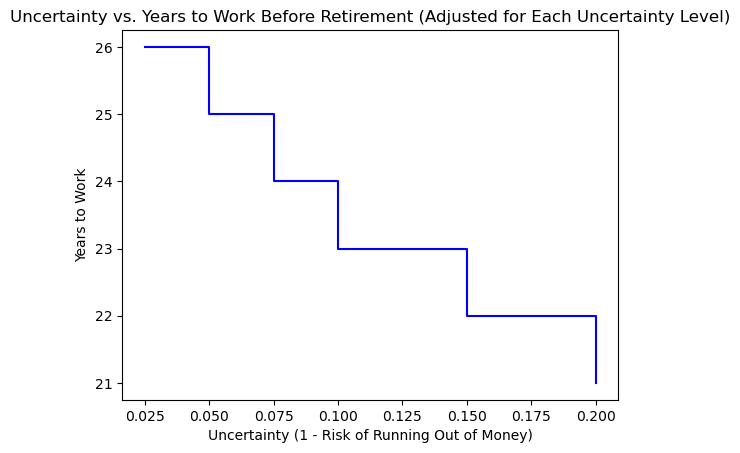

Uncertainty 0.025: Years to work 26.00
Uncertainty 0.050: Years to work 25.00
Uncertainty 0.075: Years to work 24.00
Uncertainty 0.100: Years to work 23.00
Uncertainty 0.125: Years to work 23.00
Uncertainty 0.150: Years to work 22.00
Uncertainty 0.175: Years to work 22.00
Uncertainty 0.200: Years to work 21.00
Simulation time: 2.81 seconds


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

# Start tracking time
start_time = time.time()

# Input parameters
simulations = 100000
starting_age = 55
starting_wealth = 200000
savings_rate = 24000
withdrawal_rate = 30000
inflation_rate = 0.025
uncertainty = 0.05  # 5% chance of running out of money
max_age = 120
cagr = 0.1068  # S&P 500 annual growth rate (source: https://curvo.eu/backtest/en/market-index/sp-500?currency=usd)
std_dev = 0.1473  # S&P 500 standard deviation (source: https://curvo.eu/backtest/en/market-index/sp-500?currency=usd)

# Death rates from age 55 to 119 (source: https://www.ssa.gov/oact/STATS/table4c6.html)
death_rates = [
    0.00977, 0.010567, 0.011398, 0.012291, 0.013224, 0.014267, 0.015353, 0.016484,
    0.017617, 0.018759, 0.019914, 0.021104, 0.022423, 0.023847, 0.025357, 0.02705,
    0.02897, 0.031188, 0.033754, 0.036747, 0.040563, 0.044308, 0.048498, 0.053229,
    0.058778, 0.064617, 0.070947, 0.077834, 0.085686, 0.094809, 0.10509, 0.116592,
    0.129306, 0.142732, 0.157638, 0.174458, 0.193027, 0.21293, 0.232657, 0.251826,
    0.270943, 0.289756, 0.307998, 0.325393, 0.341662, 0.358746, 0.376683, 0.395517,
    0.415293, 0.436058, 0.45786, 0.480753, 0.504791, 0.530031, 0.556532, 0.584359,
    0.613577, 0.644256, 0.676468, 0.710292, 0.745806, 0.783097, 0.822251, 0.863364,
    0.906532
]  

# Function to simulate one scenario
def simulate_retirement(starting_wealth, savings_rate, withdrawal_rate, inflation_rate, max_age, cagr, std_dev, death_rates):
    wealth = starting_wealth
    age = starting_age
    years_working = 0

    # Simulate the years until retirement
    while age < max_age:
        death_probability = death_rates[age - starting_age]
        if np.random.rand() < death_probability:
            break  # Person dies
        
        # Simulate investment return for the year
        annual_return = np.random.normal(cagr, std_dev)
        wealth *= (1 + annual_return)
        
        # Add savings for the year
        wealth += savings_rate
        
        years_working += 1
        age += 1

        # Check if retirement is possible (wealth sustains withdrawals until max age)
        years_left = max_age - age  # Remaining lifetime
        temp_wealth = wealth
        temp_withdrawal_rate = withdrawal_rate

        # Simulate withdrawals until the maximum age
        for _ in range(years_left):
            temp_wealth -= temp_withdrawal_rate  # Subtract yearly withdrawal
            temp_withdrawal_rate *= (1 + inflation_rate)  # Adjust withdrawal for inflation
            if temp_wealth < 0:
                break  # Wealth runs out before max age

        if temp_wealth >= 0:  # Wealth sustains retirement until max age
            break

    # Simulate retirement withdrawals
    while age < max_age:
        death_probability = death_rates[age - starting_age]
        if np.random.rand() < death_probability:
            break  # Person dies
        
        # Apply inflation to the withdrawal rate
        withdrawal_rate *= (1 + inflation_rate)
        
        # Simulate investment return during retirement
        annual_return = np.random.normal(cagr, std_dev)
        wealth *= (1 + annual_return)
        
        # Subtract the withdrawal amount
        wealth -= withdrawal_rate

        if wealth <= 0:
            break  # Money runs out

        age += 1

    return years_working

# Run the simulation once
def run_simulation(simulations):
    results = []
    for _ in range(simulations):
        years_working = simulate_retirement(starting_wealth, savings_rate, withdrawal_rate, inflation_rate, max_age, cagr, std_dev, death_rates)
        results.append(years_working)
    
    return results

# Get simulation results
simulation_results = run_simulation(simulations)

# Calculate the average number of years to work
avg_years_to_work = np.mean(simulation_results)
print(f"Average years to work: {avg_years_to_work:.2f}")

# Uncertainty levels (risk of running out of money)
uncertainty = np.array([0.025, 0.050, 0.075, 0.100, 0.125, 0.150, 0.175, 0.200])

# Calculate years to work at each uncertainty level using precomputed simulation results
# Note: Instead of running the simulation for each uncertainty level individually, we first run the simulation once
# and then calculate the years to work for each uncertainty level by using the precomputed results.
# For each uncertainty level, we find the corresponding percentile of the simulation results
# (based on the remaining risk of running out of money) and append it to the years_to_work_at_uncertainty list.
years_to_work_at_uncertainty = []

for u in uncertainty:
    # Calculate years to work for the current uncertainty level
    years_to_work_at_uncertainty.append(np.percentile(simulation_results, (1 - u) * 100))

# Create a step plot for the relationship
plt.step(uncertainty, years_to_work_at_uncertainty, where='post', linestyle='-', color='b')
plt.xlabel('Uncertainty (1 - Risk of Running Out of Money)')
plt.ylabel('Years to Work')
plt.title('Uncertainty vs. Years to Work Before Retirement (Adjusted for Each Uncertainty Level)')
plt.show()

# Output the results
for u, years in zip(uncertainty, years_to_work_at_uncertainty):
    print(f"Uncertainty {u:.3f}: Years to work {years:.2f}")

# Calculate the time taken
end_time = time.time()
execution_time = end_time - start_time
print(f"Simulation time: {execution_time:.2f} seconds")